# 03 — Test-set evaluation, error analysis and prediction on new text
The saved model is loaded from `model/` (no retraining).

In [1]:
import os, sys
# Colab: clone the repository first
if "google.colab" in sys.modules and not os.path.exists("src"):
    !git clone https://github.com/dilya17/kz-profanity-detection-DL26.git
    %cd kz-profanity-detection-DL26
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Working dir:", os.getcwd())

Cloning into 'kz-profanity-detection-DL26'...
remote: Enumerating objects: 79, done.
remote: Counting objects: 100% (79/79), done.
remote: Compressing objects: 100% (77/77), done.
remote: Total 79 (delta 33), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (79/79), 997.01 KiB | 3.13 MiB/s, done.
Resolving deltas: 100% (33/33), done.
/content/kz-profanity-detection-DL26
Working dir: /content/kz-profanity-detection-DL26


In [2]:
import json
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
from src.predict import load_model, predict
from src.preprocess import normalize

bundle = load_model("model")
print("Threshold:", bundle["cfg"]["threshold"])

Threshold: 0.7


## 1. Test-set prediction (run once)

In [3]:
test = pd.read_csv("data/test.csv")
preds = [predict(bundle, t) for t in test.text]
test["prob"] = [p["probability"] for p in preds]
test["pred"] = [p["label"] for p in preds]

P, R, F, _ = precision_recall_fscore_support(test.label, test.pred, average="binary")
cm = confusion_matrix(test.label, test.pred)
tn, fp, fn, tp = cm.ravel()
metrics = {"n_test": len(test), "n_clean": int((test.label == 0).sum()), "n_profane": int(test.label.sum()),
           "precision": round(P, 4), "recall": round(R, 4), "f1": round(F, 4),
           "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
           "threshold": bundle["cfg"]["threshold"]}
json.dump(metrics, open("results/test_metrics.json", "w"), indent=2)
metrics

{'n_test': 481,
 'n_clean': 120,
 'n_profane': 361,
 'precision': 0.9882,
 'recall': 0.928,
 'f1': 0.9571,
 'TN': 116,
 'FP': 4,
 'FN': 26,
 'TP': 335,
 'threshold': 0.7}

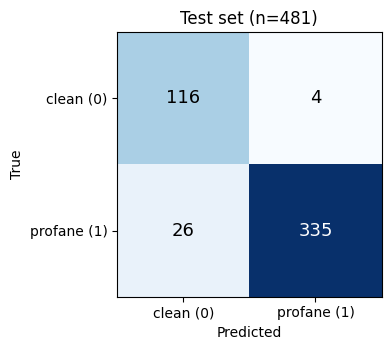

In [4]:
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm, cmap="Blues")
names = ["clean (0)", "profane (1)"]
ax.set_xticks([0, 1], names); ax.set_yticks([0, 1], names)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_title(f"Test set (n={len(test)})")
plt.tight_layout(); plt.savefig("results/confusion_matrix.png", dpi=150); plt.show()

**False positive (FP):** a clean review flagged as profane → it may be hidden unfairly.
**False negative (FN):** a profane review the model missed → users still see it.

## 2. Errors and hard examples

In [5]:
test[["text", "label", "pred", "prob", "domain", "matched"]].to_csv("results/test_predictions.csv", index=False)
pd.set_option("display.max_colwidth", 120)
print("False positives:")
display(test[(test.label == 0) & (test.pred == 1)][["text", "prob", "domain"]])
print("False negatives:")
display(test[(test.label == 1) & (test.pred == 0)][["text", "prob", "matched"]])

False positives:


,text,prob,domain
366,Яндекс приложение кирип былай караап корсендерш таксовать етііп быт шытқо программаларың детский иградан жаманғо нау...,0.9650,appstore
412,Көрбақ қақбас қатын мал,0.7864,appstore
421,Албасты керек емес ойын жынды вирусный,0.9400,appstore
465,Акуанаримдеги Фотографтар кайыршылар! Аферист мошенниктер! Отирик для себя снимаем деп отирик айтып шыккан сон 10000...,0.9464,mapping


False negatives:


,text,prob,matched
16,Жалаптар,0.3093,жалап
31,Боқ. Боқтың боғы. 💩💩💩,0.4368,бок
41,Алиишер!!! Куку ептааа...,0.6366,ебтвоюмать
64,Неге жарнама көп болады?говно🤮🤮,0.2121,говно
71,Апаруды ойлап тапқан шешеңді сыйлайындар бұл не?! Жол ақысы қалайша сонша өсіп кетеді? Мыналарың масқара ғой шешелер...,0.1391,шешенди
94,Тупойлар қолдарың сынсын мынандай боқ жасап оқытып отыр бізді,0.6736,бок
111,Күшті гезгоу сиақты маиниак болғанда ғой Күшті блады👍👍👍😎😎😎,0.5527,бля
128,мурад абдылданың қасына келсең шешңның амы бензема,0.5523,ам
149,1. Қазақ тілін көтіне қыстырмайды. 2. Банк несиені өте көп пайызбен береді. ЖАУАП БЕРІҢДЕР!,0.1444,кот
161,Акенды оданша жай бб ойнау керек андагыны жогалт мааал былай сены сыгем,0.4504,сиг


In [6]:
# Borderline cases: probability close to the threshold
t = bundle["cfg"]["threshold"]
test.assign(dist=(test.prob - t).abs()).sort_values("dist").head(10)[["text", "label", "pred", "prob"]]

,text,label,pred,prob
227,Итин амы,1,0,0.6878
94,Тупойлар қолдарың сынсын мынандай боқ жасап оқытып отыр бізді,1,0,0.6736
347,Мікссс сен малсын тез тартып жатыр деп өтірік айтып жатырсың үнемі бір ойынға кірсен менікі тез тартып жатыр деп мал...,1,1,0.7332
46,Анаң амы,1,1,0.7335
306,Күшті бірақ қата берет😡 б#ә,1,1,0.7367
351,Сутер ашпайды наху ашпайды,1,1,0.7376
335,каншык оиын Сериозна айтам б,1,1,0.7392
41,Алиишер!!! Куку ептааа...,1,0,0.6366
358,Е анаңны амы,1,0,0.6350
7,Өте жақсы бірақ көп боқ жеген адамдар көп шығады,1,1,0.7666


## 3. Prediction on new comments
Includes spellings that are **not** in the keyword list, to check generalization beyond it.

In [7]:
examples = [
    "Сапасы өте нашар, ақшамды қайтарыңыз",          # negative but clean
    "Жеткізу кешікті, курьер ақымақ екен",            # mild insult -> 0 by our rules
    "Керемет тауар, рахмет!",
    "kotakbas magazin",                                # Latin script
    "қ0тақ тауар екен",                                # digit instead of letter
    "с*к* сапасы жоқ",                                 # masked
]
for e in examples:
    print(predict(bundle, e), "|", e)

{'label': 0, 'probability': 0.0002} | Сапасы өте нашар, ақшамды қайтарыңыз
{'label': 0, 'probability': 0.0002} | Жеткізу кешікті, курьер ақымақ екен
{'label': 0, 'probability': 0.0} | Керемет тауар, рахмет!
{'label': 1, 'probability': 1.0} | kotakbas magazin
{'label': 1, 'probability': 0.7749} | қ0тақ тауар екен
{'label': 1, 'probability': 1.0} | с*к* сапасы жоқ


In [8]:
# Custom text
predict(bundle, "Мәтінді осында жазыңыз")

{'label': 0, 'probability': 0.0025}